# 26 · Set 8: train Qwen2.5 0.5B longer, then cascade 0.5B → 0.6B → 0.8B and Llama → Qwen with votes (A100)

**One notebook, resumable.** It trains the smallest model, then runs the whole cascade on the 400 test questions.

| Stage | What happens |
|---|---|
| 1. Train | **Qwen2.5 0.5B** (`Qwen/Qwen2.5-0.5B-Instruct`) learns to shortlist, same recipe as notebooks 23a/25a/25b but **trained longer: 2 passes over the 12,000 training questions** (24,000 examples seen). Validation checkpoints after 4k, 8k, 12k, 16k, 20k, 24k; the best on the 300 validation questions is kept |
| 2. Merge | The adapters already trained in 25a (Qwen3 0.6B), 25b (Qwen3.5 0.8B) and 23a (Qwen 3B, kept as the reference) are merged again from Drive |
| 3. Retrieve | All four shortlist the 400 test questions, now **recording their token probability** (their confidence) |
| 4. Answer | Llama 8B and Qwen 32B answer on every shortlist a cascade can end on (with token probabilities); Qwen 32B also gives 4 sampled answers (temperature 0.7) where a vote may be needed |
| 5. Analyse (CPU) | The policies below, thresholds fitted inside training folds |

**The cascade being tested:**

| Step | Rule |
|---|---|
| Retrieve | 0.5B shortlists. If it is **unsure** (low token probability) → 0.6B also shortlists. They **agree** → accept. They differ → 0.8B breaks the tie; no majority → the union of the three |
| Answer | Llama 8B answers. If it is **unsure** → Qwen 32B answers too. They **agree** → accept. They differ → 4 sampled Qwen answers join a **majority vote** |
| Fitted in training folds | The two "unsure" thresholds: the cheapest setting within 0.5 point of the best training accuracy (5-fold cross-validation × 5) |
| Compared with | The cheap fixed setup (AgentTTS's pick), each fine-tuned retriever alone with Qwen 32B (incl. 3B: 84.2%), each step always run, a random gate escalating the same share, Llama-or-Qwen oracle |
| Compute | Every model actually run is charged (each sample with its full prompt) |

**My estimate:** training 2.5–3 hours (25a's 0.6B took 87 min for one pass); merging about 5 min; retrieval about 10 min;
answers and samples about 50–70 min; analysis a few minutes. **About 4–4.5 hours in total.** If the session stops, run the
notebook again: every stage continues from where it stopped.

Output: `runs/Set_3__self-learnt-retrieval/<timestamp>_<GPU>_casc05/` with `adapter/` and `results/summary.md`, `set8_cascades.xlsx`, `charts/accuracy_vs_compute.png`.

**Runtime → Change runtime type → A100 GPU.**

In [1]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "Set_3__self-learnt-retrieval"
EXP_SET5    = "Set_2__question-reading-routers"
OLD_SWEEP_EXPERIMENT = "Set_1__3-modality-size"
FRESH_DATA  = f"{PROJECT_DIR}/data/hotpotqa_q/fresh200_c20_s43"
SMALL = {"key": "q05", "id": "Qwen/Qwen2.5-0.5B-Instruct", "dir": "Qwen2.5-0.5B-Instruct", "params": 0.49e9, "label": "Qwen2.5 0.5B"}
PREV = {"r06": ["_ftq06_12k", "q06", "Qwen3-0.6B", 600000000.0, "Qwen3 0.6B"], "r08": ["_ftq08_12k", "q08", "Qwen3.5-0.8B", 800000000.0, "Qwen3.5 0.8B"], "r3": ["_ft3_12k", "q3", "Qwen2.5-3B-Instruct", 3090000000.0, "Qwen2.5 3B"]}       # retriever -> [run tag of its training notebook, base key, base folder, parameters, label]
N_TRAIN = 12000                       # the same 12,000 training questions as notebooks 23a / 25a / 25b
N_VAL   = 300
EPOCHS  = 2                           # trained longer: two passes
CKPT_QUESTIONS = [4000, 8000, 12000, 16000, 20000, 24000]
N_SAMPLES = 4                         # Qwen 32B sampled answers for the votes
CV_REPEATS = 5
TIME_LIMIT_MIN = 600                  # stops cleanly at this limit; run the notebook again to continue
NEW_RUN = False                       # False = continue the latest run of this notebook
DRY_RUN = False                       # True = tiny model and fake answers on CPU: tests the whole notebook in a few minutes

EXPECTED_CODE = {
 "ssw.py": "c9fbdc7f6b91c58b607021b8be8c03ae2ff67dc1024fd2e24fffeb18e239ed98",
 "sweep.py": "9382292c6fe396cf79c73b212aaf6c2d677cae7f9311c3a5304f0578b52e6bb6",
 "routers.py": "8a293df1c8955716950f535cf9a3ced24439e00250173da1a3df110c0ed87304",
 "hidden.py": "574e6c1390e47c6de833a0c10b32c24eed0dee73a35eabc17f58842835e7f105",
 "final.py": "f18a6fba3d1bdd1f6700f6dc535f10ec0c41dbf5192b7b39ad097f8a1b88be53",
 "retriever_check.py": "fde08c549ecbd6bfc5527a42c731aa51dcff687a64818d68cf9cb30090e017e3",
 "ensemble.py": "5c5e87175d2484d806fda913a9555f71378a6031f050c37e89c20305942b76fc",
 "experts.py": "17ed39957e54853d178b47fa73ba328b50f0589b129ccb191a2efb0a2dea466b",
 "retft.py": "4a0d27d24459ba179c60dcce39a85285ae422dfa9e8d7cbc160e79a0a9932879",
 "casc8.py": "ba0d23a1aed58e9da5426406c0c953ae04b97c46cbaa820fa53328ea3e4c0bdd"
}

In [2]:
import subprocess, sys, os, json, shutil, time
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv,noheader 2>/dev/null",
                     shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none")
if not DRY_RUN:
    assert gpu, "No GPU: Runtime -> Change runtime type -> A100 GPU (or set DRY_RUN = True)."
    if "T4" in gpu:
        raise SystemExit("This runtime has a T4, which cannot run this: the 7B model alone (15 GB) does not fit in its memory.\n"
                         "Runtime -> Change runtime type -> A100 GPU (or G4 / L4) -> Save, then run all cells again.")
    if "A100" not in gpu and "G4" not in gpu and "RTX PRO 6000" not in gpu:
        print("Note: planned for an A100 or G4; this GPU works but timings will differ.")
GPU_TAG = "cpu" if not gpu else gpu.split(",")[0].replace("NVIDIA", "").replace("Tesla", "").strip().split()[0].split("-")[0]
T_START = time.time()

GPU: NVIDIA A100-SXM4-40GB, 40960 MiB, 8.0


In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### Check that Drive is serving the current code; find the earlier runs

In [4]:
import glob, hashlib
from datetime import datetime
from zoneinfo import ZoneInfo
def sha(p):
    return hashlib.sha256(open(p, "rb").read()).hexdigest()
CODE_DIR = "/content/set8code"
os.makedirs(CODE_DIR, exist_ok=True)
stale = []
for f, want in EXPECTED_CODE.items():
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{CODE_DIR}/{f}")
    if sha(f"{CODE_DIR}/{f}") != want:
        stale.append(f)
assert not stale, (f"Drive is serving a different version of {stale} than this notebook was made for. Wait two minutes, then "
                   "Runtime -> Disconnect and delete runtime, and run again.")
sweeps = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{OLD_SWEEP_EXPERIMENT}/*")) if "_dryrun" not in d and os.path.exists(f"{d}/results/per_question.jsonl")
          and os.path.exists(f"{d}/sweep_status.json") and json.load(open(f"{d}/sweep_status.json")).get("complete")]
fresh = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXP_SET5}/*_final")) if os.path.exists(f"{d}/step/retrieval_q7_c1_p3.jsonl")]
set6 = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXP_SET5}/*_set6")) if os.path.exists(f"{d}/step/arms_q32.jsonl")]
set7 = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*_ft*")) if "_dryrun" not in d and os.path.exists(f"{d}/step/answers_q32.jsonl")]
assert sweeps and fresh, "Needs the finished runs of notebooks 11 and 17."
OLD_SWEEP, FRESH_RUN = sweeps[-1], fresh[-1]
CACHE_RUN = set6[-1] if set6 else ""
OLD_DATA = json.load(open(f"{OLD_SWEEP}/config.json"))["data_dir"]
TRAIN_DATA = f"{PROJECT_DIR}/data/hotpotqa_train/train12000_val300_c20_hard_all_s7" + ("_dryrun" if DRY_RUN else "")
SESSION = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
tag = "_casc05_dryrun" if DRY_RUN else "_casc05"
prev = sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*{tag}"))
RUN_DIR = prev[-1] if (prev and not NEW_RUN) else f"{PROJECT_DIR}/runs/{EXPERIMENT}/{SESSION}_{GPU_TAG}{tag}"
ADAPTER = f"{RUN_DIR}/adapter"
ADAPTERS = {"r05": ADAPTER}
for r, (rtag, *_ ) in PREV.items():
    found = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*{rtag}" + ("_dryrun" if DRY_RUN else "")))
             if os.path.exists(f"{d}/adapter/train_state.json") and "chosen" in json.load(open(f"{d}/adapter/train_state.json"))]
    if found:
        ADAPTERS[r] = f"{found[-1]}/adapter"
    else:
        assert DRY_RUN, f"No finished training run *{rtag} with an adapter - needs notebooks 23a, 25a and 25b."
        ADAPTERS[r] = ADAPTER            # dry run: the tiny adapter stands in
SESSION_DIR = f"{RUN_DIR}/sessions/{SESSION}"
for d in (f"{RUN_DIR}/code", f"{RUN_DIR}/logs", f"{RUN_DIR}/step", SESSION_DIR):
    os.makedirs(d, exist_ok=True)
for f in EXPECTED_CODE:
    shutil.copy(f"{CODE_DIR}/{f}", f"{RUN_DIR}/code/{f}")
TIMES = {}
assert DRY_RUN or os.path.exists(f"{TRAIN_DATA}/val.json"), f"{TRAIN_DATA} is missing - it is built by notebook 23a"
print("Code files: current.")
print("Adapters:        ", json.dumps(ADAPTERS, indent=1))
print("Answers to reuse:", [CACHE_RUN] + set7)
print("Run folder:      ", RUN_DIR)

Code files: current.
Adapters:         {
 "r05": "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-133655_A100_casc05/adapter",
 "r06": "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-091250_A100_ftq06_12k/adapter",
 "r08": "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-091335_A100_ftq08_12k/adapter",
 "r3": "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261011-134625_A100_ft3_12k/adapter"
}
Answers to reuse: ['/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261010-191936_A100_set6', '/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261011-105549_A100_ft3b', '/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model

In [5]:
MODELS = {   # key: model, folder under models/, parameters (for compute), nominal size (for the AgentTTS budget formula)
    "q3":  {"id": "Qwen/Qwen2.5-3B-Instruct",        "dir": "Qwen2.5-3B-Instruct",        "params": 3.09e9,  "nominal": 3e9},
    "q7":  {"id": "Qwen/Qwen2.5-7B-Instruct",        "dir": "Qwen2.5-7B-Instruct",        "params": 7.62e9,  "nominal": 7e9},
    "q32": {"id": "Qwen/Qwen2.5-32B-Instruct-AWQ",   "dir": "Qwen2.5-32B-Instruct-AWQ",   "params": 32.76e9, "nominal": 32e9},
    "l3":  {"id": "meta-llama/Llama-3.2-3B-Instruct", "dir": "Llama-3.2-3B-Instruct",     "params": 3.21e9,  "nominal": 3e9},
    "l8":  {"id": "meta-llama/Llama-3.1-8B-Instruct", "dir": "Llama-3.1-8B-Instruct",     "params": 8.03e9,  "nominal": 8e9},
}
LOCAL = "/content/models"
for m in MODELS.values():
    m["path"] = f"{LOCAL}/{m['dir']}"

MODELS = {k: v for k, v in MODELS.items() if k in ("q3", "q7", "l8", "q32")}
SK = SMALL["key"]
MODELS[SK] = {"id": SMALL["id"], "dir": SMALL["dir"], "params": SMALL["params"], "nominal": SMALL["params"], "path": f"{LOCAL}/{SMALL['dir']}"}
BASES = {"r05": (SK, SMALL["dir"], SMALL["params"], SMALL["label"])} | {r: (v[1], v[2], v[3], v[4]) for r, v in PREV.items()}
FTKEY = {r: f"{r}ft" for r in BASES}
for r, (bk, bdir, params, lab) in BASES.items():
    MODELS[FTKEY[r]] = {"id": f"{lab} + LoRA ({ADAPTERS[r]})", "dir": FTKEY[r] + "_merged", "params": params, "nominal": params, "path": f"{LOCAL}/{FTKEY[r]}_merged"}
json.dump(MODELS, open(f"{RUN_DIR}/models.json", "w"), indent=1)
json.dump({"experiment": EXPERIMENT, "set": "8 cascades: Qwen2.5 0.5B (trained longer) -> 0.6B -> 0.8B; Llama -> Qwen with votes", "old_sweep": OLD_SWEEP,
           "fresh_run": FRESH_RUN, "adapters": ADAPTERS, "cache": [CACHE_RUN] + set7, "old_data": OLD_DATA, "fresh_data": FRESH_DATA, "train_data": TRAIN_DATA,
           "n_train": N_TRAIN, "epochs": EPOCHS, "n_samples": N_SAMPLES, "cv_repeats": CV_REPEATS, "gpu": gpu, "dry_run": DRY_RUN, "code": EXPECTED_CODE,
           "started": SESSION}, open(f"{RUN_DIR}/config.json", "w"), indent=1)

def minutes_left():
    return max(0.0, TIME_LIMIT_MIN - (time.time() - T_START) / 60)

def run_stage(args, log_name, script="retft.py"):
    cmd = [sys.executable, "-u", f"{CODE_DIR}/{script}"] + [str(a) for a in args]
    t0 = time.time()
    with open(f"{RUN_DIR}/logs/{log_name}", "a") as log, open(f"{SESSION_DIR}/{log_name}", "a") as slog:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            log.write(line); slog.write(line)
            if not any(k in line for k in ("it/s]", "s/it]", "Loading checkpoint", "INFO ", "(EngineCore", "WARNING ", "Warning", "warn", "Loading weights", "Writing model")):
                print(line, end="")
        p.wait()
    TIMES[log_name.replace(".log", "")] = TIMES.get(log_name.replace(".log", ""), 0) + round(time.time() - t0)
    json.dump(TIMES, open(f"{SESSION_DIR}/stage_times.json", "w"), indent=1)
    print(f"--- {log_name}: exit {p.returncode}, {time.time() - t0:.0f}s, {minutes_left():.0f} min left of the limit")
    assert p.returncode == 0, f"stage failed - see {RUN_DIR}/logs/{log_name}"

def trained():
    s = f"{ADAPTER}/train_state.json"
    return os.path.exists(s) and "chosen" in json.load(open(s))
print("0.5B trained:", trained())

0.5B trained: False


### 1. Download Qwen2.5 0.5B to Drive (first time only), copy the models, install peft

In [6]:
import importlib.util, threading
SRC = f"{PROJECT_DIR}/models/{SMALL['dir']}"
if not DRY_RUN and not (os.path.exists(f"{SRC}/config.json") and glob.glob(f"{SRC}/*.safetensors")):
    from huggingface_hub import snapshot_download
    t = time.time()
    tmp = f"/content/_dl/{SMALL['dir']}"
    print(f"downloading {SMALL['id']} ...")
    snapshot_download(repo_id=SMALL["id"], local_dir=tmp, allow_patterns=["*.json", "*.safetensors", "*.jinja", "*.txt", "*.model", "*.py", "tokenizer*"])
    shutil.copytree(tmp, SRC, dirs_exist_ok=True, ignore=shutil.ignore_patterns(".cache"))
    shutil.rmtree(tmp, ignore_errors=True)
    TIMES["download"] = round(time.time() - t)
    print(f"saved to {SRC} in {time.time() - t:.0f}s")
COPY = {"err": None, "done": set(), "seconds": {}}
def _copy_all(keys):
    try:
        for key in keys:
            m = MODELS[key]
            src = f"{PROJECT_DIR}/models/{m['dir']}"
            if not os.path.exists(f"{m['path']}/config.json"):
                assert os.path.exists(f"{src}/config.json"), f"{src} missing."
                t = time.time()
                shutil.rmtree(m["path"] + ".part", ignore_errors=True)
                shutil.copytree(src, m["path"] + ".part")
                os.rename(m["path"] + ".part", m["path"])
                COPY["seconds"][key] = round(time.time() - t)
            COPY["done"].add(key)
    except Exception as e:
        COPY["err"] = e

def wait_local(key):
    if DRY_RUN:
        return
    t = time.time()
    while key not in COPY["done"]:
        if COPY["err"]:
            raise COPY["err"]
        time.sleep(5)
    TIMES[f"copy_{key}"] = COPY["seconds"].get(key, 0)

if not DRY_RUN:
    os.makedirs(LOCAL, exist_ok=True)
    threading.Thread(target=_copy_all, args=([SK, "l8", "q32"],), daemon=True).start()
if importlib.util.find_spec("peft") is None:
    print("installing peft ...")
    !pip install -q peft
if not DRY_RUN and importlib.util.find_spec("fla") is None:
    print("installing flash-linear-attention (for Qwen3.5 0.8B) ...")
    !pip install -q flash-linear-attention

downloading Qwen/Qwen2.5-0.5B-Instruct ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

saved to /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/models/Qwen2.5-0.5B-Instruct in 19s
installing flash-linear-attention (for Qwen3.5 0.8B) ...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.3/45.3 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 399.6/399.6 kB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.2/819.2 kB 64.9 MB/s eta 0:00:00


### 2. Train Qwen2.5 0.5B for two passes over the training questions (resumable)

In [7]:
TRAIN = ["train", "--data_dir", TRAIN_DATA, "--out_dir", ADAPTER, "--merged_dir", MODELS[FTKEY["r05"]]["path"], "--n_train", N_TRAIN, "--n_val", N_VAL,
         "--epochs", EPOCHS, "--ckpt_questions"] + CKPT_QUESTIONS + ["--save_every_questions", 1000, "--micro_batch", 4]
if DRY_RUN:
    if not os.path.exists(f"{TRAIN_DATA}/val.json"):
        run_stage(["build_train", "--hotpot_train", f"{PROJECT_DIR}/AgentTTS/data/HotpotQA/hotpotqa-dev.json", "--out_dir", TRAIN_DATA,
                   "--n_train", 80, "--n_val", 12, "--pool", 1500], "build_train.log")
    if not trained():
        run_stage(TRAIN + ["--backend", "tiny", "--n_train", 40, "--n_val", 6, "--grad_accum", 4, "--micro_batch", 2, "--max_len", 9000,
                           "--ckpt_questions", 20, 40, 80, "--save_every_questions", 16], "train.log")
elif not trained():
    wait_local(SK)
    run_stage(TRAIN + ["--base", MODELS[SK]["path"], "--time_limit_min", max(5.0, minutes_left() - 120)], "train.log")
TRAIN_DONE = trained()
if TRAIN_DONE:
    print("Training curve:")
    for row in json.load(open(f"{ADAPTER}/train_state.json"))["curve"]:
        print(f"  {row['training questions seen']:>6} seen: both gold found {100 * row['both gold passages found']:.1f}%, exact {100 * row['exactly the gold passages']:.1f}%")
print("\nTraining complete." if TRAIN_DONE else "\nTraining NOT COMPLETE YET - run this notebook again to continue from the last resume point.")


[05:38:01] loaded /content/models/Qwen2.5-0.5B-Instruct as Qwen2ForCausalLM (AutoModelForCausalLM)
[05:39:30] training examples: 11959 (dropped 41 longer than 4096 tokens); mean length 2663 tokens
[05:39:31] LoRA r=16: 8.8M trainable parameters; 2989 optimizer steps (8 questions each, micro-batches of 4); validation checkpoints at steps [500, 1000, 1500, 2000, 2500, 2989]; resume point every 125 steps
[05:40:24]   step 25/2989 | loss 0.614 | 0.9 min this session
[05:41:16]   step 50/2989 | loss 0.490 | 1.8 min this session
[05:42:07]   step 75/2989 | loss 0.469 | 2.6 min this session
[05:43:01]   step 100/2989 | loss 0.437 | 3.5 min this session
[05:43:54]   step 125/2989 | loss 0.353 | 4.4 min this session
[05:44:46]   step 150/2989 | loss 0.296 | 0.9 min this session
[05:45:37]   step 175/2989 | loss 0.255 | 1.7 min this session
[05:46:28]   step 200/2989 | loss 0.229 | 2.6 min this session
[05:47:20]   step 225/2989 | loss 0.244 | 3.4 min this session
[05:48:11]   step 250/2989 | l

### 3. Merge the four fine-tuned retrievers (0.5B from this run; 0.6B, 0.8B, 3B from notebooks 25a, 25b, 23a)

In [8]:
if TRAIN_DONE:
    for r, (bk, bdir, params, lab) in BASES.items():
        run_stage(["merge", "--adapter_dir", ADAPTERS[r], "--merged_dir", MODELS[FTKEY[r]]["path"], "--base", f"{PROJECT_DIR}/models/{bdir}"]
                  + (["--backend", "tiny"] if DRY_RUN else []), "merge.log")

[07:45:18] already merged: /content/models/r05ft_merged
--- merge.log: exit 0, 10s, 471 min left of the limit

[07:46:07] loaded /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/models/Qwen3-0.6B as Qwen3ForCausalLM (AutoModelForCausalLM)

[07:46:28] merged /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-091250_A100_ftq06_12k/adapter/ckpt_step1494 -> /content/models/r06ft_merged
--- merge.log: exit 0, 70s, 470 min left of the limit

[07:47:06] loaded /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/models/Qwen3.5-0.8B as Qwen3_5ForCausalLM (AutoModelForCausalLM)

[07:47:39] merged /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-091335_A100_ftq08_12k/adapter/ckpt_step1494 -> /content/models/r08ft_merged
--- merge.log: exit 0, 72s, 469 min left of the limit

[07:50:08] loaded /content/drive/MyDrive/0_EngD_assignments/0

### 4. Retrieval with confidence, then answers and samples (vLLM)

In [9]:
BACKEND = "mock" if DRY_RUN else "vllm"
BASE_ARGS = ["--old_sweep", OLD_SWEEP, "--old_data", OLD_DATA, "--fresh_run", FRESH_RUN, "--fresh_data", FRESH_DATA, "--run_dir", RUN_DIR,
             "--models_json", f"{RUN_DIR}/models.json"]
SETS = BASE_ARGS + ["--backend", BACKEND]
STEP = f"{RUN_DIR}/step"
ALL_DONE = False
if TRAIN_DONE:
    if not DRY_RUN and importlib.util.find_spec("vllm") is None:
        t = time.time()
        !pip install -q vllm
        !pip uninstall -y -q torchaudio   # Colab's torchaudio is built for another CUDA version and breaks imports
        chk = subprocess.run([sys.executable, "-c", "from vllm import LLM; import vllm, torch; print('vLLM', vllm.__version__, '| torch', torch.__version__)"],
                             capture_output=True, text=True)
        print(chk.stdout or chk.stderr[-2000:])
        assert chk.returncode == 0, "vLLM does not import - Runtime -> Disconnect and delete runtime, then run again."
        TIMES["install_vllm"] = round(time.time() - t)
    run_stage(["retrieve"] + SETS + ["--variants"] + list(BASES) + ["--add_variant"] + [f"{r}:{FTKEY[r]}:{BASES[r][3]}, fine-tuned" for r in BASES], "retrieve.log")
    run_stage(["shortlists"] + BASE_ARGS, "shortlists.log", script="casc8.py")
    for key in ("l8", "q32"):
        wait_local(key)
    # every shortlist a cascade can end on: fresh answers with token probabilities (answers from notebook 25c-style runs with them are reused)
    run_stage(["answer", "--only_extra", "--require_logprob", "--extra_shortlists", f"{STEP}/cascade_shortlists.jsonl", "--tag", "notebook 26",
               "--cache_answers"] + set7 + SETS, "answer.log")
    # the cheap fixed setup's shortlists: Qwen 32B answers, mostly reused from notebooks 21-25
    run_stage(["answer", "--only_extra", "--models", "q32", "--extra_shortlists", f"{STEP}/ref_shortlists.jsonl", "--tag", "notebook 26",
               "--cache_run", CACHE_RUN, "--cache_answers"] + set7 + SETS, "answer_ref.log")
    run_stage(["sample", "--model", "q32", "--n", N_SAMPLES, "--temperature", 0.7, "--extra_shortlists", f"{STEP}/sample_shortlists.jsonl"] + SETS, "sample.log")
    ALL_DONE = True

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.6/320.6 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 95.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 70.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.0/426.0 kB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 121.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 56.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 105.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729

### 5. The cascades, thresholds fitted inside training folds (CPU)

[08:18:13] results -> /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-133655_A100_casc05/results
--- analyze.log: exit 0, 20s, 438 min left of the limit


# Set 8: cascades of small fine-tuned retrievers and answerers

Code version 8.0. 400 test questions. Thresholds fitted inside training folds (5-fold cross-validation x 5); the cheapest setting within 0.5 point of the best training accuracy. Compute counts every model that runs.

## Headline

| Policy | Accuracy (corrected label) | Exact match | Escalated | Compute vs the cheap fixed setup | vs cheap fixed setup (points) | low | high | vs 3B fine-tuned -> Qwen 32B (points) | low  | high  |
|---|---|---|---|---|---|---|---|---|---|---|
| Cheap fixed setup: Qwen 7B retrieves, Qwen 32B answers (AgentTTS's pick) | 76.8% | 57.5% | 0.0% | 0.0% | +0.0 | +0.0 | +0.0 | -7.8 | -10.8 | -5.0 |
| Qwen2.5 0.5B alone -> Qwen 32B | 79.5% | 60.0% | 0.0% | -58.3% | +2.8 | -0.7 | +6.2 | -5.0 | -7.5 | -2.7 |
| Qwen2.5 0.5B alone -> Llama 8B | 74.8% | 52.8% | 0.0% | -84.9% | -2.0 | -6.0 | +2.0 | -9.7 | -13.5 | -6.0 |
| Qwen2.5 3B alone -> Qwen 32B | 84.5% | 64.2% | 0.0% | -42.4% | +7.8 | +5.0 | +10.8 | +0.0 | +0.0 | +0.0 |
| 0.5B -> 0.6B -> 0.8B chain, always entered (agree -> accept; 0.8B breaks ties; else union) -> Qwen 32B | 84.0% | 63.5% | 0.0% | -53.2% | +7.3 | +4.5 | +10.3 | -0.5 | -1.8 | +0.7 |
| [0.5B->0.6B->0.8B always] Oracle: Llama if right, else Qwen (needs the answer key) | 86.8% | 68.0% | 0.0% | -71.6% | +10.0 | +7.0 | +13.0 | +2.3 | +0.5 | +4.2 |
| FULL CASCADE, every step always run | 83.8% | 63.0% | 100.0% | 4.3% | +7.0 | +4.0 | +10.0 | -0.7 | -2.3 | +0.7 |
| CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Qwen 32B answers | 83.5% | 63.2% | 49.0% | -55.1% | +6.7 | +3.7 | +9.7 | -1.0 | -2.5 | +0.2 |
| CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Llama 8B answers | 77.3% | 54.0% | 33.9% | -82.9% | +0.6 | -3.2 | +4.2 | -7.2 | -10.7 | -3.9 |
| FULL CASCADE: 0.5B; unsure -> 0.6B -> 0.8B; Llama answers; unsure -> Qwen; agree -> accept, else Qwen samples vote | 82.8% | 62.9% | 97.0% | -3.2% | +6.0 | +2.9 | +9.0 | -1.7 | -3.5 | -0.0 |
|    random gate, same share: FULL CASCADE: 0.5B; unsure -> 0.6B -> 0.8B; Llama answers; unsure -> Qwen; agree -> accept, else Qwen samples vote | 81.8% | 61.5% | 97.0% | -2.3% | +5.1 | +2.2 | +8.1 | -2.7 | -4.3 | -1.1 |

## Retrieval

| Retrieval | Both gold passages found | Mean shortlist size | Mean retrievers run | Retrieval TFLOPs per question |
|---|---|---|---|---|
| Qwen2.5 0.5B alone | 82.8% | 2.00 | 1.00 | 2.70 |
| Qwen3 0.6B alone | 90.5% | 2.00 | 1.00 | 3.31 |
| Qwen3.5 0.8B alone | 90.8% | 2.00 | 1.00 | 4.42 |
| Qwen2.5 3B alone | 91.8% | 2.00 | 1.00 | 17.04 |
| 0.5B -> 0.6B -> 0.8B chain, always entered (agree -> accept; 0.8B breaks ties; else union) | 93.5% | 2.08 | 2.16 | 6.75 |
| 0.5B + 0.6B + 0.8B, union of all three | 95.2% | 2.23 | 3.00 | 10.44 |
| Qwen 7B, step-by-step (the cheap fixed setup) | 79.5% | 2.86 | 1.00 | 46.71 |

## Final accuracy, all policies

| Policy | Kind | Accuracy (corrected label) | Exact match | Escalated | Compute vs the cheap fixed setup | vs cheap fixed setup (points) | low | high | vs 3B fine-tuned -> Qwen 32B (points) | low  | high  |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Cheap fixed setup: Qwen 7B retrieves, Qwen 32B answers (AgentTTS's pick) | fixed | 76.8% | 57.5% | 0.0% | 0.0% | +0.0 | +0.0 | +0.0 | -7.8 | -10.8 | -5.0 |
| Qwen2.5 0.5B alone -> Qwen 32B | fixed / always | 79.5% | 60.0% | 0.0% | -58.3% | +2.8 | -0.7 | +6.2 | -5.0 | -7.5 | -2.7 |
| Qwen2.5 0.5B alone -> Llama 8B | fixed / always | 74.8% | 52.8% | 0.0% | -84.9% | -2.0 | -6.0 | +2.0 | -9.7 | -13.5 | -6.0 |
| Qwen3 0.6B alone -> Qwen 32B | fixed / always | 83.2% | 62.7% | 0.0% | -57.8% | +6.5 | +3.5 | +9.5 | -1.2 | -2.5 | +0.0 |
| Qwen3 0.6B alone -> Llama 8B | fixed / always | 77.5% | 54.5% | 0.0% | -84.3% | +0.8 | -3.0 | +4.3 | -7.0 | -10.3 | -3.7 |
| Qwen3.5 0.8B alone -> Qwen 32B | fixed / always | 84.0% | 63.5% | 0.0% | -56.5% | +7.3 | +4.2 | +10.3 | -0.5 | -1.7 | +0.7 |
| Qwen3.5 0.8B alone -> Llama 8B | fixed / always | 77.2% | 54.8% | 0.0% | -83.1% | +0.5 | -3.3 | +4.2 | -7.3 | -10.5 | -4.0 |
| Qwen2.5 3B alone -> Qwen 32B | fixed / always | 84.5% | 64.2% | 0.0% | -42.4% | +7.8 | +5.0 | +10.8 | +0.0 | +0.0 | +0.0 |
| Qwen2.5 3B alone -> Llama 8B | fixed / always | 78.2% | 55.2% | 0.0% | -69.1% | +1.5 | -2.2 | +5.0 | -6.2 | -9.5 | -3.2 |
| 0.5B -> 0.6B -> 0.8B chain, always entered (agree -> accept; 0.8B breaks ties; else union) -> Qwen 32B | fixed / always | 84.0% | 63.5% | 0.0% | -53.2% | +7.3 | +4.5 | +10.3 | -0.5 | -1.8 | +0.7 |
| 0.5B -> 0.6B -> 0.8B chain, always entered (agree -> accept; 0.8B breaks ties; else union) -> Llama 8B | fixed / always | 78.2% | 54.8% | 0.0% | -80.3% | +1.5 | -2.2 | +5.0 | -6.2 | -9.5 | -3.0 |
| 0.5B + 0.6B + 0.8B, union of all three -> Qwen 32B | fixed / always | 83.0% | 63.2% | 0.0% | -47.7% | +6.2 | +3.5 | +9.0 | -1.5 | -3.0 | -0.2 |
| 0.5B + 0.6B + 0.8B, union of all three -> Llama 8B | fixed / always | 79.2% | 55.0% | 0.0% | -75.9% | +2.5 | -1.3 | +6.2 | -5.2 | -8.7 | -2.0 |
| [0.5B] Qwen 32B, greedy + 4 samples, vote | fixed / always | 79.5% | 59.8% | 0.0% | 97.4% | +2.8 | -0.5 | +6.0 | -5.0 | -7.5 | -2.5 |
| [0.5B] Llama and Qwen always; agree -> accept, else Qwen samples vote | fixed / always | 80.0% | 60.0% | 100.0% | 3.4% | +3.3 | +0.0 | +6.8 | -4.5 | -7.0 | -2.2 |
| [0.5B] Oracle: Llama if right, else Qwen (needs the answer key) | oracle | 83.0% | 65.2% | 0.0% | -74.8% | +6.2 | +3.0 | +9.8 | -1.5 | -4.2 | +1.2 |
| [0.5B->0.6B->0.8B always] Qwen 32B, greedy + 4 samples, vote | fixed / always | 84.0% | 63.2% | 0.0% | 104.7% | +7.3 | +4.5 | +10.3 | -0.5 | -2.2 | +1.2 |
| [0.5B->0.6B->0.8B always] Llama and Qwen always; agree -> accept, else Qwen samples vote | fixed / always | 83.8% | 63.0% | 100.0% | 4.3% | +7.0 | +4.0 | +10.0 | -0.7 | -2.3 | +0.7 |
| [0.5B->0.6B->0.8B always] Oracle: Llama if right, else Qwen (needs the answer key) | oracle | 86.8% | 68.0% | 0.0% | -71.6% | +10.0 | +7.0 | +13.0 | +2.3 | +0.5 | +4.2 |
| FULL CASCADE, every step always run | fixed / always | 83.8% | 63.0% | 100.0% | 4.3% | +7.0 | +4.0 | +10.0 | -0.7 | -2.3 | +0.7 |
| CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Qwen 32B answers | fitted in folds | 83.5% | 63.2% | 49.0% | -55.1% | +6.7 | +3.7 | +9.7 | -1.0 | -2.5 | +0.2 |
|    random gate, same share: CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Qwen 32B answers | random gate | 82.1% | 62.2% | 49.0% | -55.8% | +5.3 | +2.4 | +8.3 | -2.4 | -4.0 | -0.9 |
| CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Llama 8B answers | fitted in folds | 77.3% | 54.0% | 33.9% | -82.9% | +0.6 | -3.2 | +4.2 | -7.2 | -10.7 | -3.9 |
|    random gate, same share: CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Llama 8B answers | random gate | 75.9% | 53.1% | 33.9% | -83.4% | -0.8 | -4.6 | +2.9 | -8.6 | -12.0 | -5.2 |
| [0.5B] Llama; unsure (token probability) -> Qwen's answer replaces it | fitted in folds | 79.0% | 59.8% | 89.2% | -50.4% | +2.3 | -1.2 | +5.6 | -5.5 | -8.0 | -3.2 |
|    random gate, same share: [0.5B] Llama; unsure (token probability) -> Qwen's answer replaces it | random gate | 78.9% | 59.2% | 89.2% | -50.4% | +2.2 | -1.2 | +5.5 | -5.6 | -8.1 | -3.3 |
| [0.5B] Llama; unsure (token probability) -> Qwen; agree -> accept, else Qwen samples vote | fitted in folds | 79.5% | 59.8% | 89.7% | -4.7% | +2.8 | -0.7 | +6.1 | -5.0 | -7.5 | -2.7 |
|    random gate, same share: [0.5B] Llama; unsure (token probability) -> Qwen; agree -> accept, else Qwen samples vote | random gate | 79.4% | 59.3% | 89.7% | -4.6% | +2.7 | -0.7 | +6.0 | -5.1 | -7.5 | -2.7 |
| [0.5B] Llama; unsure (stated confidence) -> Qwen's answer replaces it | fitted in folds | 79.5% | 60.0% | 100.0% | -46.2% | +2.8 | -0.7 | +6.2 | -5.0 | -7.5 | -2.7 |
|    random gate, same share: [0.5B] Llama; unsure (stated confidence) -> Qwen's answer replaces it | random gate | 79.5% | 60.0% | 100.0% | -46.2% | +2.8 | -0.7 | +6.2 | -5.0 | -7.5 | -2.7 |
| [0.5B] Llama; unsure (stated confidence) -> Qwen; agree -> accept, else Qwen samples vote | fitted in folds | 80.0% | 60.0% | 100.0% | 3.4% | +3.3 | +0.0 | +6.8 | -4.5 | -7.0 | -2.2 |
|    random gate, same share: [0.5B] Llama; unsure (stated confidence) -> Qwen; agree -> accept, else Qwen samples vote | random gate | 80.0% | 60.0% | 100.0% | 3.4% | +3.3 | +0.0 | +6.8 | -4.5 | -7.0 | -2.2 |
| [0.5B->0.6B->0.8B always] Llama; unsure (token probability) -> Qwen's answer replaces it | fitted in folds | 83.3% | 63.1% | 90.0% | -45.1% | +6.6 | +3.6 | +9.6 | -1.2 | -2.7 | +0.2 |
|    random gate, same share: [0.5B->0.6B->0.8B always] Llama; unsure (token probability) -> Qwen's answer replaces it | random gate | 83.6% | 62.5% | 90.0% | -45.0% | +6.9 | +4.0 | +9.8 | -0.9 | -2.2 | +0.3 |
| [0.5B->0.6B->0.8B always] Llama; unsure (token probability) -> Qwen; agree -> accept, else Qwen samples vote | fitted in folds | 83.1% | 62.9% | 90.0% | -3.9% | +6.3 | +3.3 | +9.4 | -1.4 | -3.2 | +0.1 |
|    random gate, same share: [0.5B->0.6B->0.8B always] Llama; unsure (token probability) -> Qwen; agree -> accept, else Qwen samples vote | random gate | 83.2% | 62.0% | 90.0% | -4.2% | +6.5 | +3.7 | +9.4 | -1.2 | -2.8 | +0.1 |
| [0.5B->0.6B->0.8B always] Llama; unsure (stated confidence) -> Qwen's answer replaces it | fitted in folds | 84.0% | 63.5% | 100.0% | -41.1% | +7.3 | +4.5 | +10.3 | -0.5 | -1.8 | +0.7 |
|    random gate, same share: [0.5B->0.6B->0.8B always] Llama; unsure (stated confidence) -> Qwen's answer replaces it | random gate | 84.0% | 63.5% | 100.0% | -41.1% | +7.3 | +4.5 | +10.3 | -0.5 | -1.8 | +0.7 |
| [0.5B->0.6B->0.8B always] Llama; unsure (stated confidence) -> Qwen; agree -> accept, else Qwen samples vote | fitted in folds | 83.8% | 63.0% | 100.0% | 4.3% | +7.0 | +4.0 | +10.0 | -0.7 | -2.3 | +0.7 |
|    random gate, same share: [0.5B->0.6B->0.8B always] Llama; unsure (stated confidence) -> Qwen; agree -> accept, else Qwen samples vote | random gate | 83.8% | 63.0% | 100.0% | 4.3% | +7.0 | +4.0 | +10.0 | -0.7 | -2.3 | +0.7 |
| FULL CASCADE: 0.5B; unsure -> 0.6B -> 0.8B; Llama answers; unsure -> Qwen; agree -> accept, else Qwen samples vote | fitted in folds | 82.8% | 62.9% | 97.0% | -3.2% | +6.0 | +2.9 | +9.0 | -1.7 | -3.5 | -0.0 |
|    random gate, same share: FULL CASCADE: 0.5B; unsure -> 0.6B -> 0.8B; Llama answers; unsure -> Qwen; agree -> accept, else Qwen samples vote | random gate | 81.8% | 61.5% | 97.0% | -2.3% | +5.1 | +2.2 | +8.1 | -2.7 | -4.3 | -1.1 |

## Fitted policies against a random gate escalating the same share

| Policy | Escalated | vs random gate, same share (points) | low   | high   |
|---|---|---|---|---|
| CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Qwen 32B answers | 49.0% | +1.4 | +0.6 | +2.3 |
| CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Llama 8B answers | 33.9% | +1.4 | +0.4 | +2.5 |
| [0.5B] Llama; unsure (token probability) -> Qwen's answer replaces it | 89.2% | +0.1 | -0.7 | +0.7 |
| [0.5B] Llama; unsure (token probability) -> Qwen; agree -> accept, else Qwen samples vote | 89.7% | +0.1 | -0.7 | +0.7 |
| [0.5B] Llama; unsure (stated confidence) -> Qwen's answer replaces it | 100.0% | +0.0 | +0.0 | +0.0 |
| [0.5B] Llama; unsure (stated confidence) -> Qwen; agree -> accept, else Qwen samples vote | 100.0% | +0.0 | +0.0 | +0.0 |
| [0.5B->0.6B->0.8B always] Llama; unsure (token probability) -> Qwen's answer replaces it | 90.0% | -0.3 | -1.1 | +0.3 |
| [0.5B->0.6B->0.8B always] Llama; unsure (token probability) -> Qwen; agree -> accept, else Qwen samples vote | 90.0% | -0.2 | -1.0 | +0.4 |
| [0.5B->0.6B->0.8B always] Llama; unsure (stated confidence) -> Qwen's answer replaces it | 100.0% | +0.0 | +0.0 | +0.0 |
| [0.5B->0.6B->0.8B always] Llama; unsure (stated confidence) -> Qwen; agree -> accept, else Qwen samples vote | 100.0% | +0.0 | +0.0 | +0.0 |
| FULL CASCADE: 0.5B; unsure -> 0.6B -> 0.8B; Llama answers; unsure -> Qwen; agree -> accept, else Qwen samples vote | 97.0% | +0.9 | -0.1 | +1.8 |

## Fit on one half, test on the other

| Policy | Fit -> test | Accuracy (corrected label) | Exact match | Escalated | Cheap fixed setup on the same questions | 3B fine-tuned -> Qwen 32B on the same questions | Compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|
| CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Qwen 32B answers | old -> fresh | 82.0% | 61.0% | 48.5% | 72.5% | 83.0% | -55.4% |
| CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Qwen 32B answers | fresh -> old | 83.0% | 64.0% | 14.5% | 81.0% | 86.0% | -56.8% |
| CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Llama 8B answers | old -> fresh | 78.5% | 54.5% | 24.0% | 72.5% | 83.0% | -83.6% |
| CHAIN (retrieval): 0.5B; unsure -> 0.6B, then 0.8B on disagreement -> Llama 8B answers | fresh -> old | 76.0% | 53.5% | 14.5% | 81.0% | 86.0% | -83.6% |
| [0.5B] Llama; unsure (token probability) -> Qwen's answer replaces it | old -> fresh | 77.5% | 57.5% | 91.0% | 72.5% | 83.0% | -49.8% |
| [0.5B] Llama; unsure (token probability) -> Qwen's answer replaces it | fresh -> old | 73.5% | 52.0% | 3.0% | 81.0% | 86.0% | -83.4% |
| [0.5B] Llama; unsure (token probability) -> Qwen; agree -> accept, else Qwen samples vote | old -> fresh | 77.0% | 56.5% | 91.0% | 72.5% | 83.0% | -6.9% |
| [0.5B] Llama; unsure (token probability) -> Qwen; agree -> accept, else Qwen samples vote | fresh -> old | 73.5% | 52.0% | 3.0% | 81.0% | 86.0% | -79.3% |
| [0.5B] Llama; unsure (stated confidence) -> Qwen's answer replaces it | old -> fresh | 77.5% | 57.5% | 100.0% | 72.5% | 83.0% | -46.4% |
| [0.5B] Llama; unsure (stated confidence) -> Qwen's answer replaces it | fresh -> old | 76.5% | 56.0% | 5.0% | 81.0% | 86.0% | -82.6% |
| [0.5B] Llama; unsure (stated confidence) -> Qwen; agree -> accept, else Qwen samples vote | old -> fresh | 77.0% | 56.5% | 100.0% | 72.5% | 83.0% | -0.4% |
| [0.5B] Llama; unsure (stated confidence) -> Qwen; agree -> accept, else Qwen samples vote | fresh -> old | 76.5% | 56.0% | 5.0% | 81.0% | 86.0% | -74.7% |
| [0.5B->0.6B->0.8B always] Llama; unsure (token probability) -> Qwen's answer replaces it | old -> fresh | 82.5% | 61.5% | 92.0% | 72.5% | 83.0% | -44.6% |
| [0.5B->0.6B->0.8B always] Llama; unsure (token probability) -> Qwen's answer replaces it | fresh -> old | 79.5% | 57.5% | 13.5% | 81.0% | 86.0% | -74.6% |
| [0.5B->0.6B->0.8B always] Llama; unsure (token probability) -> Qwen; agree -> accept, else Qwen samples vote | old -> fresh | 82.5% | 60.5% | 92.0% | 72.5% | 83.0% | -5.6% |
| [0.5B->0.6B->0.8B always] Llama; unsure (token probability) -> Qwen; agree -> accept, else Qwen samples vote | fresh -> old | 79.0% | 57.5% | 13.5% | 81.0% | 86.0% | -63.5% |
| [0.5B->0.6B->0.8B always] Llama; unsure (stated confidence) -> Qwen's answer replaces it | old -> fresh | 82.5% | 61.5% | 100.0% | 72.5% | 83.0% | -41.6% |
| [0.5B->0.6B->0.8B always] Llama; unsure (stated confidence) -> Qwen's answer replaces it | fresh -> old | 80.0% | 59.5% | 13.0% | 81.0% | 86.0% | -74.3% |
| [0.5B->0.6B->0.8B always] Llama; unsure (stated confidence) -> Qwen; agree -> accept, else Qwen samples vote | old -> fresh | 82.5% | 60.5% | 100.0% | 72.5% | 83.0% | 0.5% |
| [0.5B->0.6B->0.8B always] Llama; unsure (stated confidence) -> Qwen; agree -> accept, else Qwen samples vote | fresh -> old | 79.5% | 58.5% | 5.0% | 81.0% | 86.0% | -69.2% |
| FULL CASCADE: 0.5B; unsure -> 0.6B -> 0.8B; Llama answers; unsure -> Qwen; agree -> accept, else Qwen samples vote | old -> fresh | 82.0% | 60.0% | 97.5% | 72.5% | 83.0% | -3.1% |
| FULL CASCADE: 0.5B; unsure -> 0.6B -> 0.8B; Llama answers; unsure -> Qwen; agree -> accept, else Qwen samples vote | fresh -> old | 78.5% | 58.0% | 58.5% | 81.0% | 86.0% | -60.1% |

## Agreement between Llama 8B and Qwen 32B

| Shortlists | Llama and Qwen agree | Qwen right when they agree | Qwen right when they disagree | Llama right when they disagree |
|---|---|---|---|---|
| 0.5B | 69.2% | 88.8% | 58.5% | 43.1% |
| 0.5B->0.6B->0.8B chain | 72.5% | 89.7% | 69.1% | 48.2% |

## Confidence signals

| Signal (on 0.5B shortlists) | Separation (AUC; 0.5 = none) | Base rate |
|---|---|---|
| 0.5B retriever token probability -> both gold passages found | 0.90 | 82.8% |
| Llama token probability -> Llama right | 0.68 | 74.8% |
| Llama stated confidence -> Llama right | 0.66 | 74.8% |
| Qwen token probability -> Qwen right | 0.69 | 79.5% |



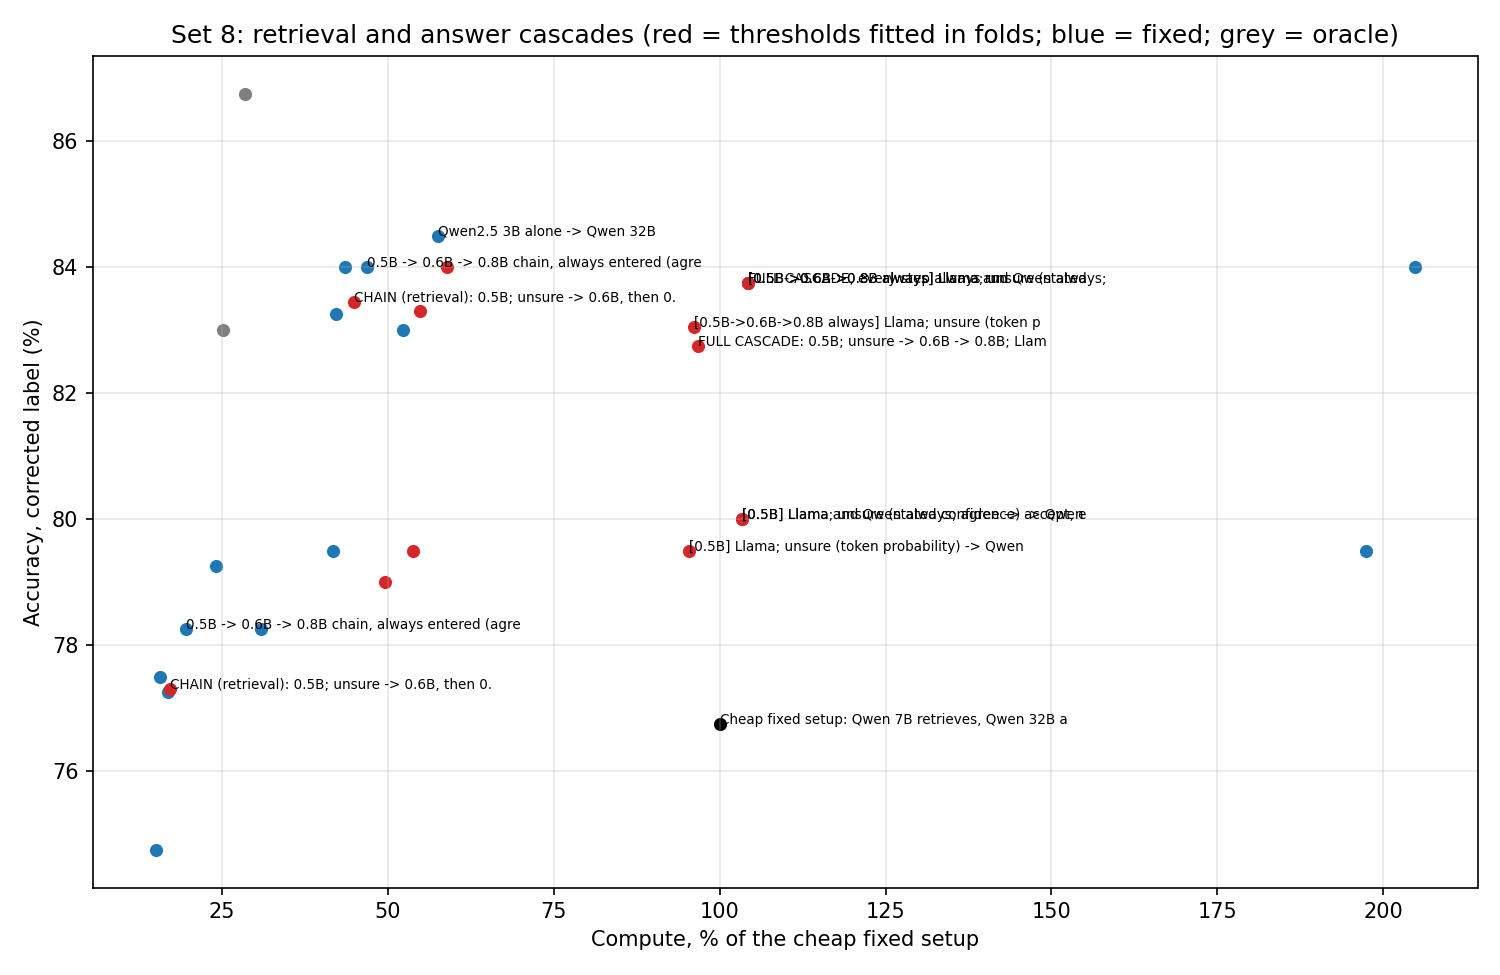

Excel workbook: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-133655_A100_casc05/results/set8_cascades.xlsx
Wall-clock this session (s): {'download': 19, 'copy_q05': 1, 'train': 7661, 'merge': 406, 'install_vllm': 201, 'retrieve': 604, 'shortlists': 3, 'copy_l8': 418, 'copy_q32': 463, 'answer': 489, 'answer_ref': 1, 'sample': 261, 'analyze': 20, 'total_session': 9721}

ALL DONE.
Saved to Drive.


In [10]:
if ALL_DONE:
    from IPython.display import Image, Markdown, display
    run_stage(["analyze", "--repeats", CV_REPEATS, "--ref_answers"] + set7 + BASE_ARGS, "analyze.log", script="casc8.py")
    display(Markdown(open(f"{RUN_DIR}/results/summary.md").read()))
    display(Image(f"{RUN_DIR}/results/charts/accuracy_vs_compute.png"))
    print("Excel workbook:", f"{RUN_DIR}/results/set8_cascades.xlsx")
TIMES["total_session"] = round(time.time() - T_START)
json.dump({"session": SESSION, "run_dir": RUN_DIR, "gpu": gpu, "seconds": TIMES, "code": EXPECTED_CODE, "complete": ALL_DONE},
          open(f"{SESSION_DIR}/session.json", "w"), indent=1)
print("Wall-clock this session (s):", TIMES)
print("\nALL DONE." if ALL_DONE else "\nNOT COMPLETE YET - run this notebook again to continue.")
try:
    drive.flush_and_unmount()
    print("Saved to Drive.")
except Exception as e:
    print("Drive flush skipped:", e)